In [1]:
import numpy as np
import pickle
import json
import os
import spectres
import matplotlib.pyplot as plt
from tqdm import tqdm

from POSEIDON.core import (create_star, create_planet, define_model,
                           make_atmosphere, compute_spectrum,
                           wl_grid_constant_R)
from POSEIDON.constants import R_J, M_J, R_Sun

In [2]:
# --- Wavelength grids ---
wl_min, wl_max, R_highres = 0.4, 10.0, 15000
wl_highres = wl_grid_constant_R(wl_min, wl_max, R_highres)
wl_binned  = np.load("free_chem_data/wl_binned.npy")

print(f"High-res grid : {len(wl_highres)} bins  ({wl_highres.min():.2f}–{wl_highres.max():.2f} μm)")
print(f"Binned grid   : {len(wl_binned)} bins  ({wl_binned.min():.2f}–{wl_binned.max():.2f} μm)")

# --- Opacity pickle (expensive to compute, load once) ---
OPAC_FILE = "opacities_created/opac_eq_chemistry.pickle"
with open(OPAC_FILE, "rb") as f:
    opac = pickle.load(f)
print("Opacities loaded.")

# --- FRECKLL pressure grid (must match what Colab used) ---
freckll_P     = np.logspace(2, -5, 100)   # 100 bar → 1e-5 bar
log_freckll_P = np.log10(freckll_P)

# --- POSEIDON pressure grid (same as Dataset A) ---
N_layers = 100
P_min    = 1.0e-7
P_max    = 10.0
P        = np.logspace(np.log10(P_max), np.log10(P_min), N_layers)
log_P    = np.log10(P)

print(f"FRECKLL P : {freckll_P.min():.1e} → {freckll_P.max():.1e} bar")
print(f"POSEIDON P: {P.min():.1e} → {P.max():.1e} bar")

High-res grid : 48283 bins  (0.40–10.00 μm)
Binned grid   : 52 bins  (0.55–7.28 μm)
Opacities loaded.
FRECKLL P : 1.0e-05 → 1.0e+02 bar
POSEIDON P: 1.0e-07 → 1.0e+01 bar


In [3]:
PROFILES_DIR = "freckll_profiles_50"

with open(f"{PROFILES_DIR}/params.json", "r") as f:
    params = json.load(f)

successful = params["successful_indices"]
print(f"Successful profiles available: {len(successful)}")

Successful profiles available: 44


In [4]:
def interp_vmr(vmr_profile):
    """Interpolate a VMR profile from FRECKLL's P grid onto POSEIDON's P grid."""
    # np.interp needs x_old increasing, but freckll_P is decreasing → flip both
    return np.interp(
        log_P,
        log_freckll_P[::-1],
        vmr_profile[::-1]
    )

def build_X_input(h2o, ch4, co, co2, nh3):
    """
    Stack interpolated VMR profiles into X_input shape (7, N_layers).
    Order must match: bulk species first [H2, He], then param species
    [H2O, CH4, CO, CO2, NH3].
    """
    he_profile = np.full(N_layers, 0.17)
    h2_profile = np.full(N_layers, 0.83)
    return np.array([
        h2_profile,
        he_profile,
        interp_vmr(h2o),
        interp_vmr(ch4),
        interp_vmr(co),
        interp_vmr(co2),
        interp_vmr(nh3),
    ])

In [5]:
bulk_species  = ["H2", "He"]
param_species = ["H2O", "CH4", "CO", "CO2", "NH3"]

model = define_model(
    "disequil_freckll_model",
    bulk_species,
    param_species,
    PT_profile = "file_read",
    X_profile  = "file_read",
)

# Sun-like star (same as Dataset A)
star = create_star(1.0 * R_Sun, 5778.0, 4.44, 0.0)

print("Model and star defined.")

Model and star defined.


In [6]:
os.makedirs("disequil_spectra", exist_ok=True)

# Check for already-completed spectra (safe to resume)
already_done = set()
for fname in os.listdir("disequil_spectra"):
    if fname.startswith("spectrum_") and fname.endswith(".npy"):
        idx = int(fname.replace("spectrum_", "").replace(".npy", ""))
        already_done.add(idx)

remaining = [i for i in successful if i not in already_done]
print(f"Already done : {len(already_done)}")
print(f"To process   : {len(remaining)}")

failed = []

for i in tqdm(remaining, desc="Computing spectra"):

    try:
        # --- Load VMR profiles ---
        data = np.load(f"{PROFILES_DIR}/profile_{i:04d}.npz")

        # --- Retrieve parameters for this profile ---
        T     = params["T"][i]
        Rp    = params["Rp_Rj"][i]
        Mp    = params["Mp_Mj"][i]

        # --- Build atmosphere inputs ---
        T_input = np.full(N_layers, T)
        X_input = build_X_input(
            data["h2o"], data["ch4"], data["co"],
            data["co2"], data["nh3"]
        )

        # --- Create planet (varies per run) ---
        R_p = Rp * R_J
        M_p = Mp * M_J
        planet = create_planet("freckll_planet", R_p, mass=M_p, T_eq=T)

        # --- Make atmosphere ---
        P_ref   = 10.0
        R_p_ref = R_p
        atmosphere = make_atmosphere(
            planet, model, P, P_ref, R_p_ref,
            T_input=T_input,
            X_input=X_input,
        )

        # --- Compute high-res spectrum ---
        spectrum_highres = compute_spectrum(
            planet, star, model, atmosphere, opac, wl_highres,
            spectrum_type="transmission"
        )

        # --- Bin to 52 channels ---
        spectrum_binned = spectres.spectres(
            wl_binned, wl_highres, spectrum_highres, verbose=False
        )

        # --- Sanity check ---
        if np.any(np.isnan(spectrum_binned)) or np.any(np.isinf(spectrum_binned)):
            print(f"[SKIP] Profile {i:04d} produced NaN/Inf")
            failed.append(i)
            continue

        # --- Save ---
        np.save(f"disequil_spectra/spectrum_{i:04d}.npy", spectrum_binned)

    except Exception as e:
        print(f"[ERROR] Profile {i:04d}: {e}")
        failed.append(i)
        continue

print(f"\nDone! Successful: {len(remaining) - len(failed)}, Failed: {len(failed)}")

Already done : 8
To process   : 36


Computing spectra: 100%|██████████| 36/36 [00:15<00:00,  2.37it/s]


Done! Successful: 36, Failed: 0


In [9]:
import os
import numpy as np

# Collect all successful spectra + matching parameters
spectra_list = []
params_list = []

for fname in sorted(os.listdir("disequil_spectra")):

    # Only process files of the form spectrum_<number>.npy
    if not (fname.startswith("spectrum_") and fname.endswith(".npy")):
        continue

    number = fname[len("spectrum_"):-4]  # remove "spectrum_" and ".npy"

    # Skip anything that isn't an integer
    if not number.isdigit():
        continue

    i = int(number)

    spec = np.load(os.path.join("disequil_spectra", fname))
    spectra_list.append(spec)

    params_list.append([
        params["Rstar_Rs"][i],
        params["Rp_Rj"][i],
        params["Mp_Mj"][i],
        params["T"][i],
        params["log_Kzz"][i],
    ])

spectra_arr = np.array(spectra_list)      # shape (N, 52)
params_arr = np.array(params_list)        # shape (N, 5)
full_arr = np.hstack([spectra_arr, params_arr])  # shape (N, 57)

# Save combined arrays
np.save("disequil_spectra/disequil_spectra.npy", spectra_arr)
np.save("disequil_spectra/disequil_params.npy", params_arr)
np.save("disequil_spectra/disequil_full.npy", full_arr)

print(f"Spectra shape : {spectra_arr.shape}")
print(f"Params shape  : {params_arr.shape}")
print(f"Full shape    : {full_arr.shape}")
print("Column order  : spectrum (52 bins) + [Rstar, Rp, Mp, T, log_Kzz]")

Spectra shape : (44, 52)
Params shape  : (44, 5)
Full shape    : (44, 57)
Column order  : spectrum (52 bins) + [Rstar, Rp, Mp, T, log_Kzz]


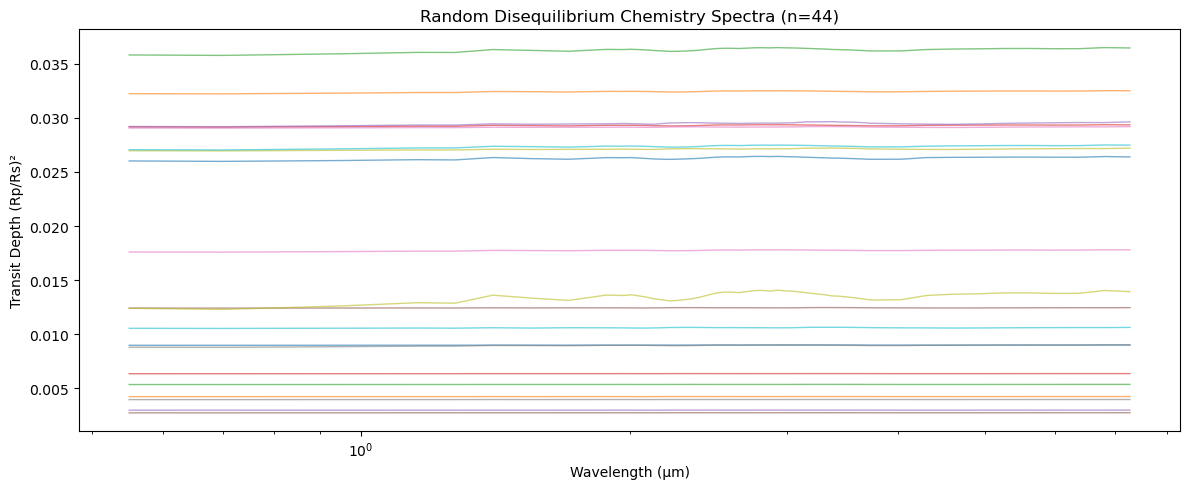

In [16]:
idx = np.random.choice(len(spectra_arr), min(20, len(spectra_arr)), replace=False)

fig, ax = plt.subplots(figsize=(12, 5))
for i in idx:
    ax.plot(wl_binned, spectra_arr[i], alpha=0.6, linewidth=1)

ax.set_xlabel("Wavelength (μm)")
ax.set_ylabel("Transit Depth (Rp/Rs)²")
ax.set_title(f"Random Disequilibrium Chemistry Spectra (n={len(spectra_arr)})")
ax.set_xscale("log")
plt.tight_layout()
plt.show()

Normalised spectra shape : (44, 52)
Mean of normalised (should be ~0) : 0.0000
Std  of normalised (should be ~1) : 0.9989


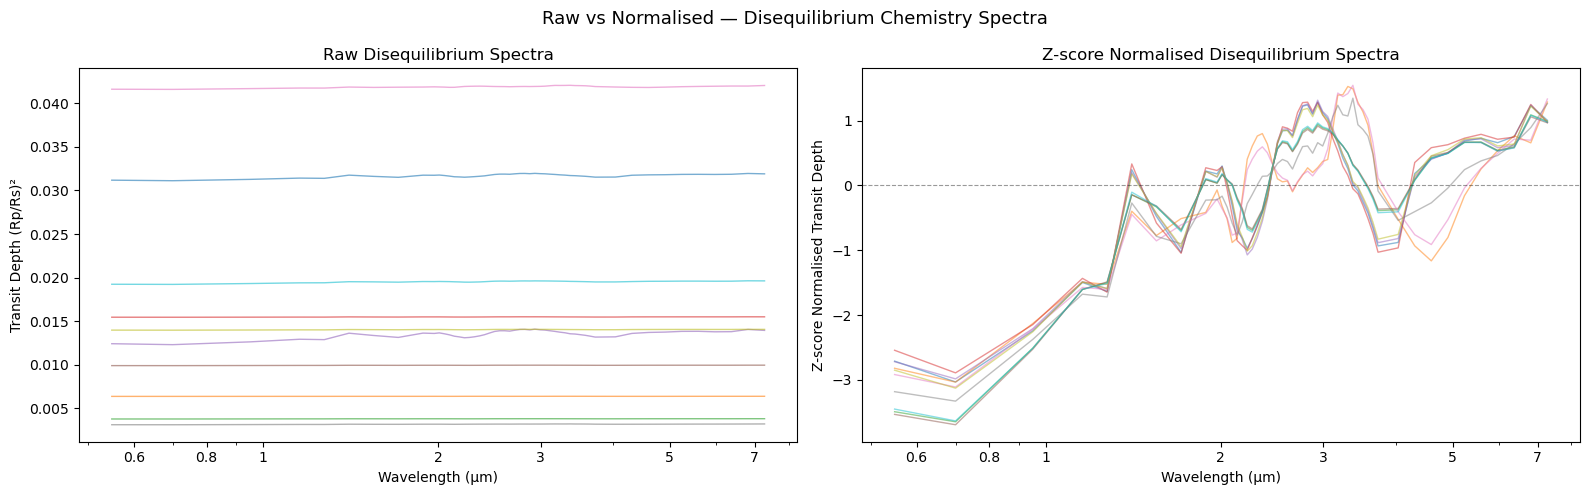

In [17]:
import matplotlib.ticker as mticker
# Z-score normalise each spectrum by its own mean and std
epsilon = 1e-8   # prevents division by zero for flat spectra

spectra_mean = spectra_arr.mean(axis=1, keepdims=True)   # shape (N, 1)
spectra_std  = spectra_arr.std(axis=1, keepdims=True)    # shape (N, 1)

spectra_norm = (spectra_arr - spectra_mean) / (spectra_std + epsilon)

print(f"Normalised spectra shape : {spectra_norm.shape}")
print(f"Mean of normalised (should be ~0) : {spectra_norm.mean():.4f}")
print(f"Std  of normalised (should be ~1) : {spectra_norm.std():.4f}")

# Plot
idx = np.random.choice(len(spectra_norm), min(10, len(spectra_norm)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left — raw spectra
for i in idx:
    axes[0].plot(wl_binned, spectra_arr[i], alpha=0.6, linewidth=1)
axes[0].set_xlabel("Wavelength (μm)")
axes[0].set_ylabel("Transit Depth (Rp/Rs)²")
axes[0].set_title("Raw Disequilibrium Spectra")


# Right — normalised spectra
for i in idx:
    axes[1].plot(wl_binned, spectra_norm[i], alpha=0.5, linewidth=1)
axes[1].set_xlabel("Wavelength (μm)")
axes[1].set_ylabel("Z-score Normalised Transit Depth")
axes[1].set_title("Z-score Normalised Disequilibrium Spectra")

axes[1].axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.4)


ticks = [0.6, 0.8, 1, 2, 3, 5, 7]  # choose values within your wavelength range

for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks])
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())

plt.suptitle("Raw vs Normalised — Disequilibrium Chemistry Spectra", fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
print(wl_binned.min(), wl_binned.max())

0.55 7.2755592
